## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Plotting defaults

sns.set_palette("Set2")
bg_color = "#FAF9F6"
grid_color = "#E5E4E2"
sns.set(rc={
    'axes.facecolor':bg_color, 
    'figure.facecolor':bg_color,
    'grid.color': grid_color,
    'axes.edgecolor': grid_color,
    'lines.markeredgecolor': grid_color,
    'scatter.edgecolors': grid_color,
})
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.serif": "Times",
})

## Load dataset

In [3]:
# data = dict()
# for file in Path("data/data").glob("*.parquet"):
#     data[file.name.split("_tx_fl_la")[0]] = pd.read_parquet(file)

## Metadata

In [6]:
data.keys()

dict_keys(['schools', 'county', 'nri', 'zcta', 'hospitals', 'floodplain', 'claims', 'census_tracts', 'svi', 'cre'])

In [36]:
data['cre'].isna().mean()

GEOID          0.000000
GEO_ID         0.000000
STATE          0.000000
COUNTY         0.000000
TRACT          0.000000
NAME           0.000000
WATER_TRACT    0.994719
POPUNI         0.000000
PRED0_E        0.000000
PRED0_M        0.000000
PRED0_PE       0.000000
PRED0_PM       0.000000
PRED12_E       0.000000
PRED12_M       0.000000
PRED12_PE      0.000000
PRED12_PM      0.000000
PRED3_E        0.000000
PRED3_M        0.000000
PRED3_PE       0.000000
PRED3_PM       0.000000
dtype: float64

In [37]:
missing_value_conventions = [
    "no missing values",
    "no missing values",
    "null",
    "no missing values",
    "no missing values",
    "no missing values",
    "null",
    "no missing values",
    "-999",
    "no missing values; none marks non-water-only tract"
]
sources = [
    "DHS Homeland Infrastructure Foundation-Level Data (HIFLD, NCES shape; https://www.dhs.gov/gmo/hifld)",
    "Census Bureau TIGER/Line Shapefills, county layer (https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html)",
    "FEMA National Risk Index, flood data only (https://www.fema.gov/about/openfema/data-sets/national-risk-index-data)",
    "Census Bureau TIGER/Line Shapefills, ZCTA layer (https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html)",
    "DHS Homeland Infrastructure Foundation-Level Data (HIFLD shape; https://www.dhs.gov/gmo/hifld)",
    "FEMA National Flood Hazard Layer (NFHL; https://www.fema.gov/flood-maps/national-flood-hazard-layer)",
    "FEMA National Flood Insurance Program (OpenFEMA FimaNfipClaims shape; https://www.fema.gov/flood-insurance)",
    "Census Bureau TIGER/Line Shapefills, census tract layer (https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html)",
    "CDC/ATSDR Social Vulnerability Index (SVI; https://www.atsdr.cdc.gov/place-health/php/svi/index.html)",
    "Census Bureau Community Resilience Estimates (CRE; https://www.census.gov/programs-surveys/community-resilience-estimates.html)"
]
join_keys = [
    "ZIP",
    "GEOID",
    "GEOID",
    "GEOID",
    "ZIP",
    np.nan,
    "GEOID",
    "GEOID",
    "GEOID",
    "GEOID"
]
geometry_types = [
    "point",
    "polygon",
    "non-spatial",
    "polygon",
    "point",
    "Multi-polygon",
    "point",
    "polygon",
    "non-spatial",
    "non-spatial"
]
CRSs = [
    "WGS84" if geotype != np.nan else np.nan
    for geotype in geometry_types
]
rows = []
for name, df in data.items():
    entry = {
        "dataset_name": name,
        "row_count": df.shape[0],
        "column_count": df.shape[1]
    }
    rows.append(entry)
metadata = pd.DataFrame(rows)
metadata["source/version"] = sources
metadata["join_key"] = join_keys
metadata["geometry_type"] = geometry_types
metadata["CRS"] = CRSs
metadata["missing_value_convention"] = missing_value_conventions

In [39]:
metadata.to_csv("data_manifest.csv")

In [41]:
if data['svi'].shape == (13385, 159):
    print("Full SVI dataset available.")

Full SVI dataset available.


## Joining

In [54]:
# Clean SVI
data['svi'] = data['svi'].replace(to_replace=-999, value=np.nan)

In [ ]:
tract_level = data['census_tracts']
for dataset in ['svi', 'nri',]:
    renamed = data[dataset].add_suffix(f"_{dataset}")
    tract_level = tract_level.merge(renamed, left_on="GEOID", right_on=f"GEOID_{dataset}",
                                    how="outer")

# tract_level = tract_level.merge(data['claims'], on="GEOID", how="right")

In [94]:
tract_level

,GEOID,STATEFP,COUNTYFP,NAME,geometry,GEOID_svi,ST_svi,STATE_svi,ST_ABBR_svi,STCNTY_svi,...,RFLD_EALT_nri,RFLD_EALS_nri,RFLD_EALR_nri,RFLD_ALRB_nri,RFLD_ALRP_nri,RFLD_ALRA_nri,RFLD_ALR_NPCTL_nri,RFLD_RISKV_nri,RFLD_RISKS_nri,RFLD_RISKR_nri
0,12001000201,12,001,2.01,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00U\x00\x0...,12001000201,12.0,Florida,FL,12001.0,...,6.218364e+02,31.580431,Very Low,2.321299e-08,1.206695e-08,0.000000,30.791272,5.961859e+02,31.171812,Very Low
1,12001000202,12,001,2.02,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00@\x00\x0...,12001000202,12.0,Florida,FL,12001.0,...,2.228510e+04,66.305752,Relatively Low,1.298790e-06,3.931784e-07,0.000000,69.571600,2.395125e+04,66.240546,Relatively Low
2,12001000301,12,001,3.01,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00Y\x00\x0...,12001000301,12.0,Florida,FL,12001.0,...,1.740787e+04,62.574864,Relatively Low,7.045062e-07,4.321516e-07,0.000000,70.796439,2.152722e+04,64.651810,Relatively Low
3,12001000302,12,001,3.02,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00o\x00\x0...,12001000302,12.0,Florida,FL,12001.0,...,1.546544e+04,60.828616,Relatively Low,3.978878e-06,4.308704e-07,0.000000,67.332128,1.858876e+04,62.529135,Relatively Low
4,12001000400,12,001,4,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x8d\x00...,12001000400,12.0,Florida,FL,12001.0,...,7.447579e+04,83.050708,Relatively Moderate,7.980708e-06,1.105502e-06,0.006385,83.546281,1.151124e+05,86.438662,Relatively Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13439,48505950402,48,505,9504.02,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\xdc\x01...,48505950402,48.0,Texas,TX,48505.0,...,3.506367e+05,95.681941,Relatively High,7.778788e-05,9.006094e-06,0.000145,95.389530,6.973554e+05,97.558626,Relatively High
13440,48507950100,48,507,9501,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x9e\x02...,48507950100,48.0,Texas,TX,48507.0,...,1.401260e+05,89.630552,Relatively Moderate,1.520768e-04,4.198836e-06,0.003525,93.005613,2.354540e+05,92.539124,Relatively High
13441,48507950200,48,507,9502,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00+\x03\x0...,48507950200,48.0,Texas,TX,48507.0,...,2.792179e+04,69.665547,Relatively Moderate,4.122464e-06,3.162714e-08,0.002158,84.997769,4.915607e+04,76.344956,Relatively Moderate
13442,48507950301,48,507,9503.01,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\xaf\x01...,48507950301,48.0,Texas,TX,48507.0,...,4.708709e+05,96.882119,Relatively High,1.992320e-04,4.707266e-06,0.007207,95.680767,9.152841e+05,98.187699,Relatively High


## Corr

In [4]:
tract_level = pd.read_parquet('../wk1_deliverables/tract_evidence.parquet')

In [5]:
crit_corr = tract_level[['H_raw', 'E_raw', 'L_raw', 'V_raw', 'F_raw']].corr()
crit_corr.to_csv("data/data/criterion_correlations.csv")

In [6]:
crit_corr

,H_raw,E_raw,L_raw,V_raw,F_raw
H_raw,1.000000,-0.036708,0.096454,0.019473,0.036102
E_raw,-0.036708,1.000000,0.305820,0.014998,-0.017277
L_raw,0.096454,0.305820,1.000000,-0.004589,0.016946
V_raw,0.019473,0.014998,-0.004589,1.000000,0.143834
F_raw,0.036102,-0.017277,0.016946,0.143834,1.000000


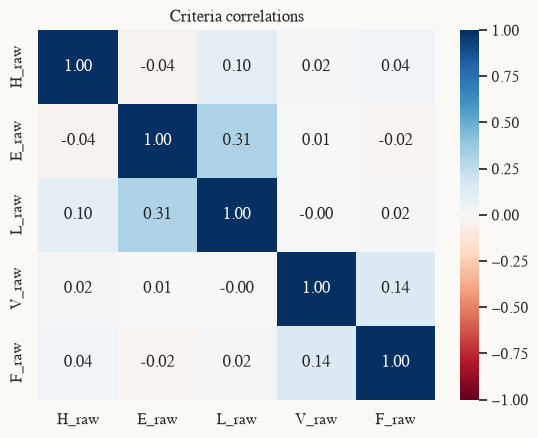

In [7]:
fig, axs = plt.subplots()
sns.heatmap(
    crit_corr, 
    annot=True, fmt=".2f",
    cmap='RdBu', vmin=-1, vmax=1
)
plt.title("Criteria correlations")
fig.savefig("../wk1_deliverables/criteria_correlations.png",
                dpi=400,
    bbox_inches="tight")

## County summary

In [8]:
county_counts = pd.read_csv("data/data/county_tract_counts.csv")

Text(0.5, 1.0, 'Tract Counts by County')

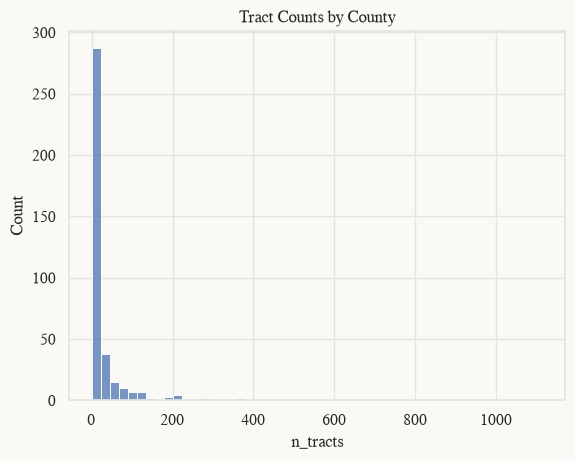

In [9]:
sns.histplot(county_counts['n_tracts'], bins=50)
plt.title("Tract Counts by County")

In [10]:
county_profiles = pd.read_csv("../wk1_deliverables/county_profile.csv")

In [11]:
county_profiles.columns

Index(['county_geoid', 'n_tracts', 'H_missing', 'E_missing', 'L_missing',
       'V_missing', 'H_gt_0', 'L_gt_0', 'hos_gt_0', 'school_gt_0', 'F_gt_0',
       'H_min', 'H_max', 'H_mean', 'H_med', 'H_std', 'H_unq_ct', 'E_min',
       'E_max', 'E_mean', 'E_med', 'E_std', 'E_unq_ct', 'L_min', 'L_max',
       'L_mean', 'L_med', 'L_std', 'L_unq_ct', 'V_min', 'V_max', 'V_mean',
       'V_med', 'V_std', 'V_unq_ct', 'F_min', 'F_max', 'F_mean', 'F_med',
       'F_std', 'F_unq_ct'],
      dtype='str')

In [12]:
unq_ct = [col for col in county_profiles.columns if "unq_ct" in col]
missing = [col for col in county_profiles.columns if "missing" in col]
std_cols = [col for col in county_profiles.columns if "std" in col]
mean_cols = [col for col in county_profiles.columns if "mean" in col]
med_cols = [col for col in county_profiles.columns if "med" in col]
min_cols = [col for col in county_profiles.columns if "min" in col]
max_cols = [col for col in county_profiles.columns if "max" in col]



In [13]:
county_profiles[unq_ct].sum() / county_profiles['n_tracts'].sum()

H_unq_ct    0.036076
E_unq_ct    0.868715
L_unq_ct    0.879946
V_unq_ct    0.971363
F_unq_ct    0.165799
dtype: float64

In [14]:
county_profiles[missing].mean()

H_missing    0.010106
E_missing    0.010106
L_missing    0.010106
V_missing    0.016722
dtype: float64

In [15]:
six_metro_counties = pd.read_csv("data/data/six_metro_counties.csv")

## Policy Separability

In [16]:
metrics = [
    "jaccard_top10",
    "overlap_top20pct",
    "kendall_tau",
]
metrics_formatted = [
    "Top 10 Jaccard",
    "Top 20% Overlap",
    "Kendall's $\\tau$",
]

MIN_TRACT_COUNT = 20

### Criteria

In [17]:
(county_profiles['n_tracts'] < MIN_TRACT_COUNT).sum()

np.int64(281)

In [18]:
large_counties = county_profiles[county_profiles['n_tracts'] >= MIN_TRACT_COUNT]

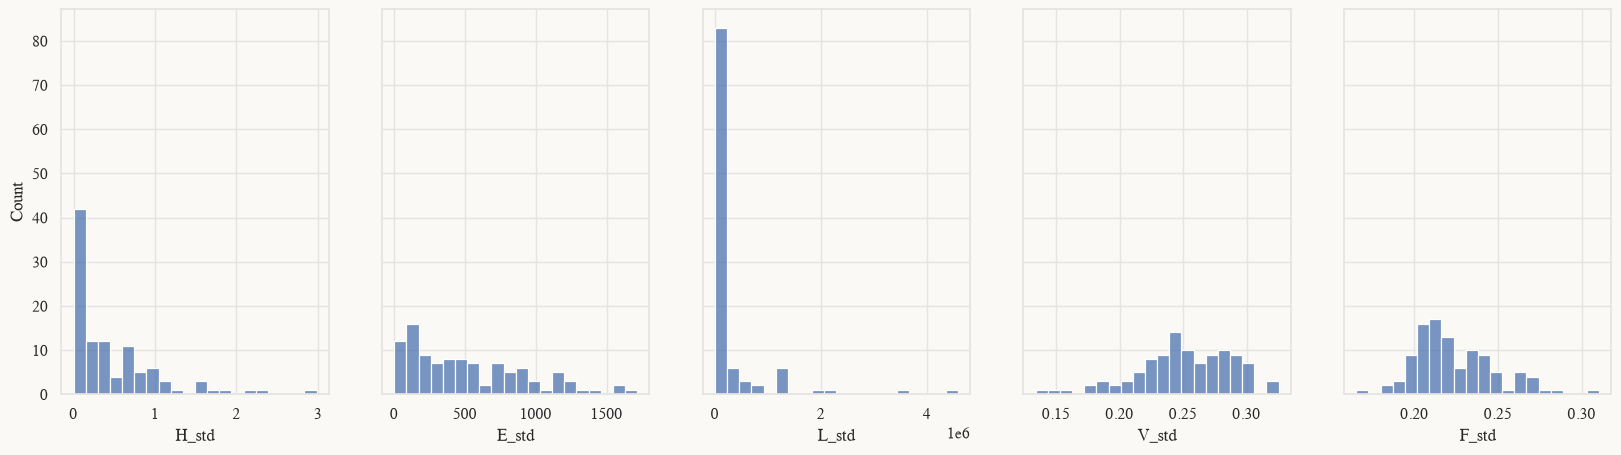

In [19]:
fig, axs = plt.subplots(1, 5, figsize=(20, 5), sharey=True)
for i, col in enumerate(std_cols):
    sns.histplot(large_counties[col], 
                 ax=axs[i], bins=20, stat='count')

In [20]:
tract_level['H_raw'].value_counts(normalize=True).cumsum()

H_raw
0.000000    0.121887
2.291667    0.198609
5.250000    0.258506
1.458333    0.301877
4.875000    0.337994
              ...   
4.375000    0.999701
0.041667    0.999776
0.010000    0.999850
0.125000    0.999925
3.083333    1.000000
Name: proportion, Length: 91, dtype: float64

<Axes: xlabel='H_raw', ylabel='Count'>

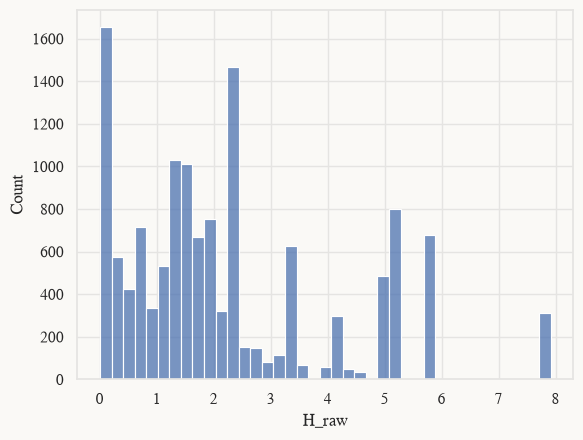

In [21]:
sns.histplot(tract_level['H_raw'])

### Policies

In [22]:
county_info = six_metro_counties.merge(county_profiles, on='county_geoid', how='left')
list(county_info[county_info['n_tracts'] < MIN_TRACT_COUNT]['county_name'])

['Liberty',
 'Waller',
 'San Jacinto',
 'Austin',
 'Chambers',
 'Wise',
 'Caldwell',
 'Atascosa',
 'Wilson',
 'Medina',
 'Kendall',
 'Bandera',
 'St. Bernard',
 'St. Charles',
 'St. John the Baptist',
 'Plaquemines',
 'St. James']

In [34]:
p_sep = pd.read_parquet("data/data/outputs/policy_separability.parquet")
p_sep = (p_sep
    .merge(
        county_info[['cbsa_title', 'n_tracts', 'county_name']],
        how='left', left_on='metro_area_name', right_on='cbsa_title')
    )
p_sep_clean = p_sep[p_sep['n_tracts'] >= MIN_TRACT_COUNT]
p_sep.groupby(['policy_a', 'policy_b'])[metrics].mean()

jaccard_top10  overlap_top20pct  kendall_tau
policy_a policy_b                                              
P1       P2             0.137701          0.675965     0.692179
         P3             0.059277          0.507011     0.476498
         P4             0.132543          0.526484     0.598488
         P5             0.049575          0.471215     0.512256
         P6             0.083200          0.624581     0.638735
P2       P3             0.081996          0.586177     0.547851
         P4             0.164439          0.608321     0.670055
         P5             0.066243          0.448408     0.435023
         P6             0.151070          0.658097     0.667539
P3       P4             0.020053          0.416539     0.408312
         P5             0.043062          0.396457     0.356230
         P6             0.120581          0.670434     0.647544
P4       P5             0.051302          0.393061     0.399810
         P6             0.058347          0.550153     0.619140
P5       P6             0.274595          0.677566     0.653020

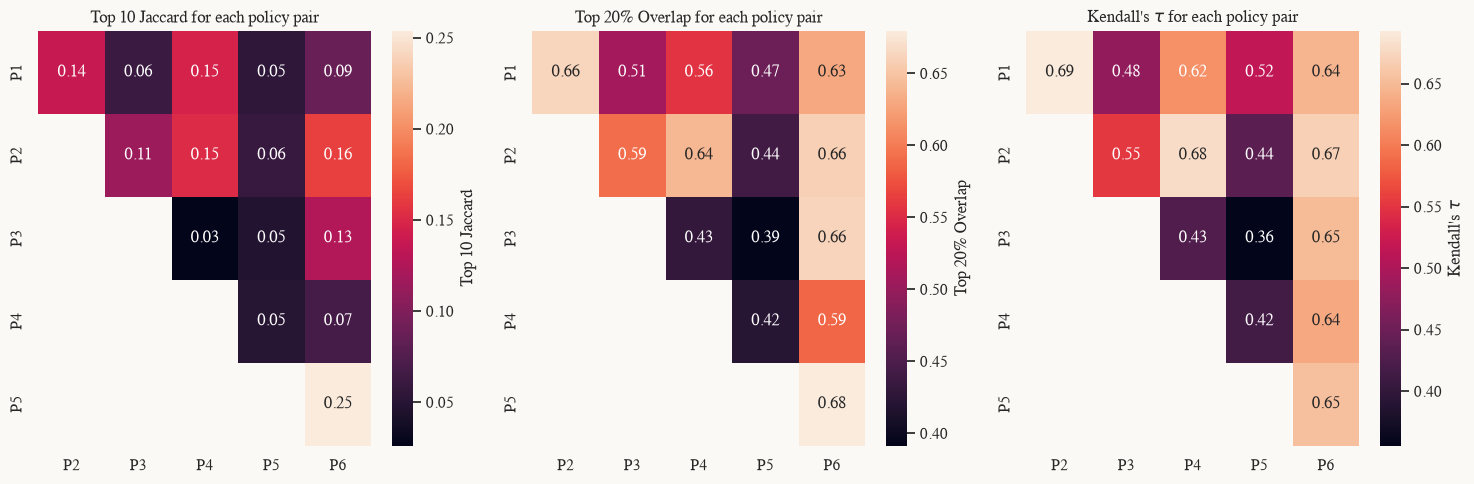

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, ax in enumerate(axs):
    pivot = p_sep_clean.pivot_table(
    index='policy_a',
    columns='policy_b',
    values=metrics[i],
    aggfunc='mean'
)
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        # vmin=0, vmax=1,
        cbar_kws={
            "label": metrics_formatted[i]
        },
        ax=ax
    )
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_title(f"{metrics_formatted[i]} for each policy pair")
    ax.grid()
plt.tight_layout()
fig.savefig(
    "../wk1_deliverables/p_sep_heatmap.png",
    dpi=400,
    bbox_inches="tight"
)

In [39]:
agg_funcs = dict(
       list(zip(metrics, ['mean']*len(metrics)))
       +
       [('metro_area_name', 'first'),
        ('county_name', 'first'),
        ('n_tracts', 'mean')]
)
(p_sep.groupby('metro_area_name').agg(agg_funcs)
 .sort_values(by=metrics, ascending=True))

,jaccard_top10,overlap_top20pct,kendall_tau,metro_area_name,county_name,n_tracts
metro_area_name,,,,,,
"Houston-Pasadena-The Woodlands, TX",0.051531,0.621584,0.619188,"Houston-Pasadena-The Woodlands, TX",Harris,161.500000
"Miami-Fort Lauderdale-West Palm Beach, FL",0.059273,0.558238,0.563037,"Miami-Fort Lauderdale-West Palm Beach, FL",Miami-Dade,499.000000
"New Orleans-Metairie, LA",0.092715,0.450469,0.482118,"New Orleans-Metairie, LA",Orleans,53.000000
"Dallas-Fort Worth-Arlington, TX",0.111444,0.558455,0.564598,"Dallas-Fort Worth-Arlington, TX",Dallas,154.909091
"San Antonio-New Braunfels, TX",0.119241,0.526734,0.529143,"San Antonio-New Braunfels, TX",Bexar,62.625000
"Austin-Round Rock-San Marcos, TX",0.172081,0.536667,0.542733,"Austin-Round Rock-San Marcos, TX",Travis,100.600000


<Axes: xlabel='value', ylabel='metro_area_name'>

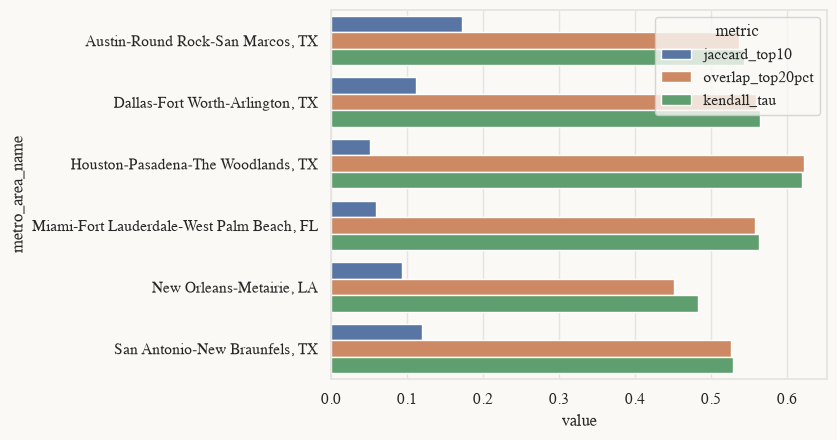

In [41]:
county_vals = (p_sep.groupby('metro_area_name')[metrics]
               .mean().reset_index()
               .melt("metro_area_name",
                     var_name="metric"))
sns.barplot(county_vals, y='metro_area_name', x='value', hue='metric')

### Leave One Out impact

In [46]:
loo_impact = pd.read_parquet("data/data/outputs/policy_separability_loo.parquet")
loo_impact = (loo_impact
    .merge(
        county_info[['cbsa_title', 'n_tracts', 'county_name']],
        how='left', left_on='metro_area_name', right_on='cbsa_title')
    )
loo_impact['loo'] = loo_impact['policy_loo'].str[-1]
loo_impact_clean = loo_impact[loo_impact['n_tracts'] >= MIN_TRACT_COUNT]

In [47]:
loo_impact_clean.groupby(['policy_parent', 'policy_loo'])[metrics].mean()

jaccard_top10  overlap_top20pct  kendall_tau
policy_parent policy_loo                                              
P3            P3_loo_E         0.093644          0.539691     0.514166
              P3_loo_V         0.114742          0.591519     0.552985
P5            P5_loo_F         0.054148          0.470289     0.515204
              P5_loo_H         0.049714          0.640222     0.589944
P6            P6_loo_E         0.668887          0.868945     0.872456
              P6_loo_F         0.290599          0.761631     0.798512
              P6_loo_H         0.612277          0.868184     0.867000
              P6_loo_L         0.644220          0.877897     0.866839
              P6_loo_V         0.321447          0.811517     0.822290

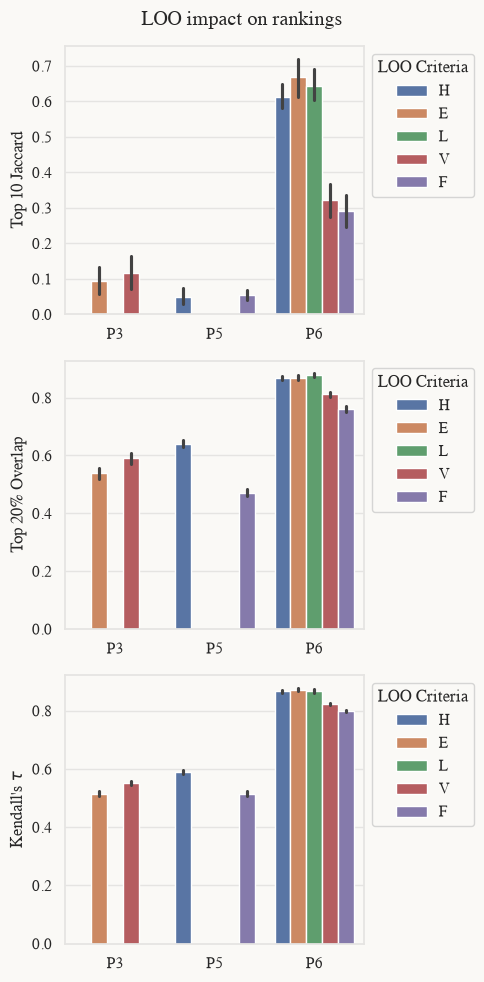

In [48]:
fig, axs = plt.subplots(3, 1, figsize=(5, 10))
for i, ax in enumerate(axs):
    metric = metrics[i]
    metric_name = metrics_formatted[i]
    sns.barplot(
        loo_impact_clean,
        x='policy_parent',
        y=metric,
        hue='loo',
        hue_order="HELVF",
        errorbar=("ci", 95),
        ax=ax
    )
    ax.set_xlabel("")
    ax.set_ylabel(metric_name)
    ax.legend(
        title="LOO Criteria",
        bbox_to_anchor=(1,1)
    )
    if i > 0:
        ax.sharex(axs[i-1])
fig.suptitle("LOO impact on rankings")
fig.tight_layout()

fig.savefig(
    "../wk1_deliverables/LOO_impact.png",
    dpi=400,
    bbox_inches="tight"
)

In [49]:
loo_impact

,metro_area_name,policy_parent,policy_loo,jaccard_top10,overlap_top20pct,kendall_tau,regret_10,cbsa_title,n_tracts,county_name,loo
0,"Austin-Round Rock-San Marcos, TX",P3,P3_loo_E,0.333333,0.58000,0.559861,0.502992,"Austin-Round Rock-San Marcos, TX",290,Travis,E
1,"Austin-Round Rock-San Marcos, TX",P3,P3_loo_E,0.333333,0.58000,0.559861,0.502992,"Austin-Round Rock-San Marcos, TX",135,Williamson,E
2,"Austin-Round Rock-San Marcos, TX",P3,P3_loo_E,0.333333,0.58000,0.559861,0.502992,"Austin-Round Rock-San Marcos, TX",46,Hays,E
3,"Austin-Round Rock-San Marcos, TX",P3,P3_loo_E,0.333333,0.58000,0.559861,0.502992,"Austin-Round Rock-San Marcos, TX",21,Bastrop,E
4,"Austin-Round Rock-San Marcos, TX",P3,P3_loo_E,0.333333,0.58000,0.559861,0.502992,"Austin-Round Rock-San Marcos, TX",11,Caldwell,E
...,...,...,...,...,...,...,...,...,...,...,...
391,"San Antonio-New Braunfels, TX",P6,P6_loo_F,0.333333,0.79798,0.792259,0.205793,"San Antonio-New Braunfels, TX",13,Atascosa,F
392,"San Antonio-New Braunfels, TX",P6,P6_loo_F,0.333333,0.79798,0.792259,0.205793,"San Antonio-New Braunfels, TX",12,Wilson,F
393,"San Antonio-New Braunfels, TX",P6,P6_loo_F,0.333333,0.79798,0.792259,0.205793,"San Antonio-New Braunfels, TX",11,Medina,F
394,"San Antonio-New Braunfels, TX",P6,P6_loo_F,0.333333,0.79798,0.792259,0.205793,"San Antonio-New Braunfels, TX",9,Kendall,F


In [62]:
df = pd.read_csv("data/data/six_metro_counties.csv")

In [63]:
df['metro_id'] = df["cbsa_title"].apply(lambda x:
    {
        'Houston-Pasadena-The Woodlands, TX':'HOU',
           'Dallas-Fort Worth-Arlington, TX':'DFW',
 'Miami-Fort Lauderdale-West Palm Beach, FL':'MFL',
          'Austin-Round Rock-San Marcos, TX':'AUS',
             'San Antonio-New Braunfels, TX':'SAN',
                  'New Orleans-Metairie, LA':'NOL'
    }[x]
    )

In [64]:
df[['metro_id', 'cbsa_title', 'county_name', 'state', 'county_geoid']].to_csv('data/data/six_metro_counties.csv', index=False)